<a href="https://colab.research.google.com/github/klissiadev/PP2.1_Perceptron/blob/main/PP21_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt
from pathlib import Path

In [29]:
# Matrículas
mat1 = "2415310025" #Ana Klissia Futado Martins
mat2 = "2415310021" #Nathalia Nobrega Silva

# Calculo do identificador
digito1 = int(mat1[-1])
digito2 = int(mat2[-1])

identificador = (digito1 + digito2) % 4
print(f"Identificador: {identificador}")

Identificador: 2


In [30]:
# Arquivos de dados
arquivoParte1 = "dataAll20262.txt"
arquivoParte2 = f"data{identificador}20262.txt"
arquivoParte3 = "dataHoldout20262.txt"

diretorio = Path(".")

arquivos = [
  arquivoParte1,
  arquivoParte2,
  arquivoParte3
]

for nome in arquivos:
  caminho = diretorio / nome
  if caminho.exists():
    print(f"Arquivo encontrado: {nome}")
  else:
    print(f"Arquivo não encontrado: {nome}")

Arquivo encontrado: dataAll20262.txt
Arquivo encontrado: data220262.txt
Arquivo encontrado: dataHoldout20262.txt


# Parte I

In [31]:
# Parâmetros iniciais da parte I
TAXA_APRENDIZADO = 0.1
LIMIAR = 0
INTERVALO_PESOS = (-0.5, 0.5)

# Cores das classes
COR_CLASSE_0 = "red"
COR_CLASSE_1 = "blue"

In [32]:
def carregarDados(arquivo):
  dados = np.load(arquivo)
  dados = np.asarray(dados, dtype=float)

  # Valida se cada exemplo contém x1, x2 e yd
  dados = dados.reshape(-1, 3)
  if not np.all(np.isfinite(dados)):
    raise ValueError("O arquivo contém valores inválidos.")

  rotulos = np.unique(dados[:, 2])
  if not np.all(np.isin(rotulos, [0, 1])):
    raise ValueError(f"Rótulos inesperados: {rotulos}")

  return dados


dados = carregarDados(arquivoParte1)

X = dados[:, :2] # coordenadas x1 e x2
y = dados[:, 2].astype(int) # classes desejadas

print("Formato dos dados:", dados.shape)
print("Quantidade de exemplos:", len(dados))
print("Classes encontradas:", np.unique(y))
print(dados[:3])

Formato dos dados: (1000, 3)
Quantidade de exemplos: 1000
Classes encontradas: [0 1]
[[ 547.91209711 -122.2431205     1.        ]
 [ 717.19583982  394.73605812    0.        ]
 [-811.64530422  951.24470327    0.        ]]


In [33]:

def treinarPerceptron(
  X,
  y,
  taxaAprendizado=0.1,
  intervaloPesos=(-0.5, 0.5),
  maxEpocas=100000
):
  # Coluna do bias
  Xbias = np.column_stack((X, np.ones(X.shape[0])))

  # Sorteio dos pesos iniciais com distribuição uniforme
  pesos = np.random.uniform(
    intervaloPesos[0],
    intervaloPesos[1],
    size=Xbias.shape[1]
  )

  pesosIniciais = pesos.copy()
  totalAjustes = 0

  for epoca in range(1, maxEpocas + 1):
    errosEpoca = 0

    for i in range(len(Xbias)):
      entrada = Xbias[i]
      saidaDesejada = y[i]

      # Potencial de ativação
      potencial = np.dot(pesos, entrada)
      # Função degrau com limiar zero
      saida = 1 if potencial >= 0 else 0
      # Atualiza os pesos se houver erro
      erro = saidaDesejada - saida

      if erro != 0:
          pesos += taxaAprendizado * erro * entrada
          totalAjustes += 1
          errosEpoca += 1

  # Convergiu
  if errosEpoca == 0:
    return {
      "pesosIniciais": pesosIniciais,
      "pesosFinais": pesos,
      "ajustes": totalAjustes,
      "epocas": epoca,
      "convergiu": True
    }

  return {
    "pesosIniciais": pesosIniciais,
    "pesosFinais": pesos,
    "ajustes": totalAjustes,
    "epocas": maxEpocas,
    "convergiu": False
  }


In [34]:

resultado = treinarPerceptron(
  X,
  y,
  taxaAprendizado=TAXA_APRENDIZADO,
  intervaloPesos=INTERVALO_PESOS
)

print("Pesos iniciais:", resultado["pesosIniciais"])
print("Pesos finais:", resultado["pesosFinais"])
print("Total de ajustes:", resultado["ajustes"])
print("Épocas executadas:", resultado["epocas"])
print("Convergiu:", resultado["convergiu"])

if not resultado["convergiu"]:
  print(
      "O algoritmo não convergiu dentro do limite. "
  )


Pesos iniciais: [ 0.3830353   0.29773801 -0.37376684]
Pesos finais: [  77.42396836 -385.87170389   -0.77376684]
Total de ajustes: 42
Épocas executadas: 100000
Convergiu: True


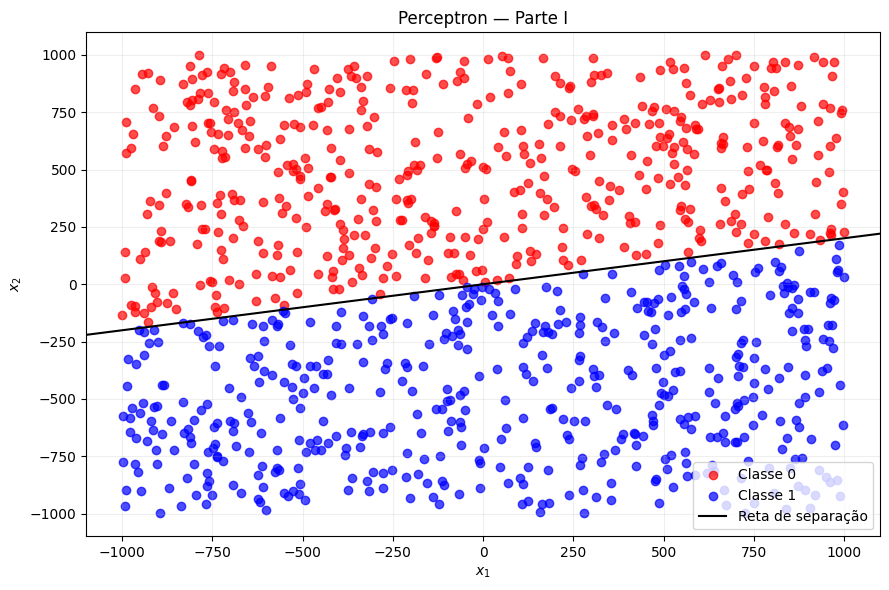

In [37]:

def plotarResultado(X, y, pesos, titulo="Perceptron — Parte I"):
  plt.figure(figsize=(9, 6))

  # Exemplos da classe 0 em vermelho
  plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    color="red",
    label="Classe 0",
    alpha=0.7
  )

  # Exemplos da classe 1 em azul
  plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Classe 1",
    alpha=0.7
  )

  w1, w2, bias = pesos

  xMin, xMax = X[:, 0].min(), X[:, 0].max()
  margemX = (xMax - xMin) * 0.05 or 0.5
  margemY = (X[:, 1].max() - X[:, 1].min()) * 0.05 or 0.5

  plt.xlim(xMin - margemX, xMax + margemX)
  plt.ylim(X[:, 1].min() - margemY, X[:, 1].max() + margemY)

  if abs(w2) > 1e-12:
    xReta = np.linspace(xMin - margemX, xMax + margemX, 200)
    yReta = -(w1 * xReta + bias) / w2
    plt.plot(xReta, yReta, color="black", label="Reta de separação")
  elif abs(w1) > 1e-12:
    xVertical = -bias / w1
    plt.axvline(
        x=xVertical,
        color="black",
        label="Reta de separação"
      )
  else:
    raise ValueError("A reta de separação não pode ser desenhada.")

  plt.xlabel("$x_1$")
  plt.ylabel("$x_2$")
  plt.title(titulo)
  plt.legend()
  plt.grid(alpha=0.2)
  plt.tight_layout()
  plt.show()

if resultado["convergiu"]:
  plotarResultado(X, y, resultado["pesosFinais"])